# Семестровая работа по введению в Машинное обучение
## Выполнил Цвиль Павел, группа ФИТ-231

# Задание:

Возьмите набор данных согласно своему варианту
(https://cloud.mail.ru/public/AQp5/X3obvSZRo). Датасет представляет собой набор
признаков, признак в последнем столбце является целевым (его надо прогнозировать).
1. Проведите предварительный анализ и подготовку данных, обработайте
пропущенные значения.
2. Проведите статистический анализ, оцените корреляции между признаками, оцените
возможные выбросы в данных, постройте поясняющие графики. Удалите из
рассмотрения признаки, которые не влияют на целевой.
3. Разбейте выборку на тренировочные и тестовые данные (60% на 40%).
4. Для предсказания целевого признака постройте следующие модели, используя
библиотеку sklearn:
a. Линейная регрессия LinearRegression()
b. Случайный лес RandomForestRegressor()
c. Метод ближайших соседей KNeighborsRegressor()
d. Метод опорных векторов SVR()
5. Для каждой модели попытайтесь добиться наилучшего возможного результата
предсказания.
6. Оцените качество работы моделей. Выведите для каждой модели ее score().
Напишите какая модель дала наилучший результат. Выведите ее значение
feature_importances_


### План работы
1. Загрузка и первичный анализ
2. Обработка пропусков
3. Корреляции и выбросы
4. Отбор признаков
5. Разбиение train/test (60/40)
6. Модели: LinearRegression, RandomForest, KNN, SVR
7. Подбор гиперпараметров
8. Оценка и выводы

# 1. Загрузка данных

### 1. Загрузка данных

В датасете нет заголовков, разделитель - точка с запятой.
Считаем файл через pandas, назовем признаки f0-f6, а последний столбец — y (то, что предсказываем).

## 1. Загрузка данных

Датасет — это текстовый файл, где значения разделены точкой с запятой `;`. 
Десятичный разделитель при этом — точка, поэтому pandas по умолчанию (с запятой) 
не справится и склеит всё в один столбец. Указываем `sep=';'`.

Заголовков в файле нет, поэтому ставим `header=None`. 
Признаки назовём `f0..f6`, целевой столбец — `y` (его и будем предсказывать).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# настройка, чтобы pandas показывал все столбцы
pd.set_option('display.max_columns', None)

# читаем файл (разделитель ';', без заголовков)
df = pd.read_csv('data/dataset_var8.csv', sep=';', header=None)

# переименовываем столбцы: f0-f6 для признаков и y для цели
df.columns = [f'f{i}' for i in range(df.shape[1] - 1)] + ['y']

# смотрим размер
print('Размер датасета:', df.shape)

# смотрим первые строки
print('\nПервые 5 строк:')
display(df.head())

Размер датасета: (100, 8)

Первые 5 строк:


,f0,f1,f2,f3,f4,f5,f6,y
0,0.113398,-0.217267,0.215167,-0.016867,-1.064496,0.370968,0.268995,11.886437
1,-0.684545,-0.718804,0.157514,0.025171,0.449468,0.405320,-0.239123,-33.260734
2,0.564893,-0.074579,1.157204,-0.389348,1.734190,NaN,-1.250852,58.674006
3,-0.748604,0.843551,0.436197,-0.899861,0.002277,NaN,1.884221,-34.333124
4,0.308416,2.528793,0.563452,0.088222,0.032436,NaN,-1.643330,29.607853


## 2. Обработка пропусков

В столбце `f5` есть пропуски (NaN). Модели sklearn не умеют с ними работать.
Я решил не удалять этот признак полностью, а заполнить пропуски медианой. 
Медиана устойчива к выбросам, в отличие от среднего значения. 

In [2]:
# Смотрим, в каких столбцах есть пропуски
print('Доля пропусков:')
print(df.isna().mean()[df.isna().mean() > 0].round(3))

# Заполняем пропуски медианой
df = df.fillna(df.median())

# Проверяем, что все чисто
print('\nОсталось пропусков:', df.isna().sum().sum())
print('Размер датасета:', df.shape)

display(df.head())

Доля пропусков:
f4    0.05
f5    0.70
dtype: float64

Осталось пропусков: 0
Размер датасета: (100, 8)


,f0,f1,f2,f3,f4,f5,f6,y
0,0.113398,-0.217267,0.215167,-0.016867,-1.064496,0.370968,0.268995,11.886437
1,-0.684545,-0.718804,0.157514,0.025171,0.449468,0.405320,-0.239123,-33.260734
2,0.564893,-0.074579,1.157204,-0.389348,1.734190,0.268823,-1.250852,58.674006
3,-0.748604,0.843551,0.436197,-0.899861,0.002277,0.268823,1.884221,-34.333124
4,0.308416,2.528793,0.563452,0.088222,0.032436,0.268823,-1.643330,29.607853


## 3. Корреляционный анализ

Корреляция Пирсона показывает силу линейной связи между признаками (от -1 до 1). 

Сначала посмотрим, какие признаки сильнее всего коррелируют с целевой переменной `y` — они будут наиболее полезны для моделей. 

Также построим тепловую карту, чтобы проверить признаки на мультиколлинеарность (когда два признака дублируют друг друга).

Корреляция с целевой переменной 'y':
f0    0.926
f1    0.116
f2    0.099
f3   -0.092
f5   -0.088
f4   -0.086
f6   -0.039
Name: y, dtype: float64


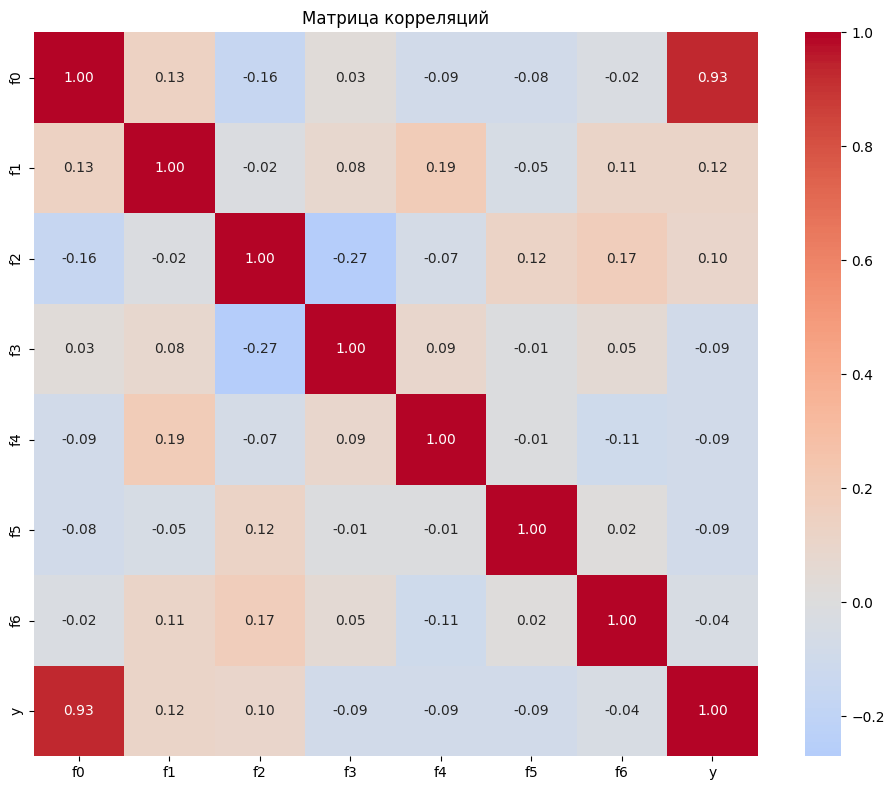

In [3]:
corr_matrix = df.corr()

# Смотрим корреляцию признаков с целью, сортируем по убыванию модуля
print("Корреляция с целевой переменной 'y':")
print(corr_matrix['y'].drop('y').sort_values(key=abs, ascending=False).round(3))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Матрица корреляций')
plt.tight_layout()
plt.show()

## 4. Анализ выбросов и отбор признаков

**Удаление признака:** По результатам корреляционного анализа признак `f6` имеет корреляцию с целью -0.039 (близко к нулю). Он не несет полезной информации

**Выбросы:** Для их поиска используем метод IQR (межквартильного размаха).

Размер после удаления f6: (100, 7)


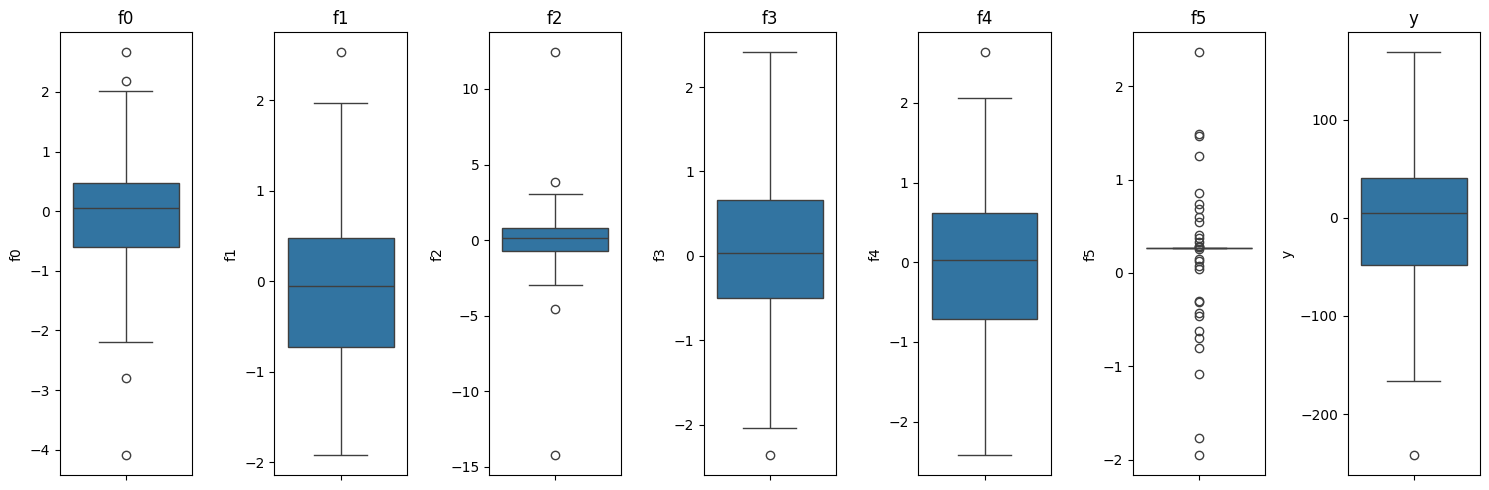


Количество выбросов в каждом столбце (по IQR):
f0: 4 шт. (4.0%)
f1: 1 шт. (1.0%)
f2: 4 шт. (4.0%)
f3: 1 шт. (1.0%)
f4: 1 шт. (1.0%)
f5: 30 шт. (30.0%)
y: 1 шт. (1.0%)


In [4]:
# 1. Удаляем f6
df = df.drop(columns=['f6'])
print('Размер после удаления f6:', df.shape)

# 2. Строим boxplot для всех оставшихся столбцов
fig, axes = plt.subplots(1, len(df.columns), figsize=(15, 5))
for ax, col in zip(axes, df.columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 3. Считаем выбросы по правилу IQR
print('\nКоличество выбросов в каждом столбце (по IQR):')
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f'{col}: {len(outliers)} шт. ({len(outliers)/len(df)*100:.1f}%)')

## 4.1. Финальная очистка данных

В столбце `f5` после заполнения медианой появилось 30% выбросов (из-за медианы). Такой признак будет вносить шум в модель, поэтому удаляем и его.

In [5]:
df = df.drop(columns=['f5'])

print('Размер датасета после очистки:', df.shape)
print('Оставшиеся столбцы:', list(df.columns))

Размер датасета после очистки: (100, 6)
Оставшиеся столбцы: ['f0', 'f1', 'f2', 'f3', 'f4', 'y']


## 5. Разбиение данных на train и test

Отделяем матрицу признаков `X` (все столбцы, кроме `y`) от целевой переменной `y`.

Делим данные на тренировочную (60%) и тестовую (40%) выборки с помощью `train_test_split`.  

In [6]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['y'])
y = df['y']

# Разбиваем: 60% в train, 40% в test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

print('Размер X_train:', X_train.shape)
print('Размер X_test:', X_test.shape)
print('Размер y_train:', y_train.shape)
print('Размер y_test:', y_test.shape)

Размер X_train: (60, 5)
Размер X_test: (40, 5)
Размер y_train: (60,)
Размер y_test: (40,)


## 6. Обучение моделей

## 6.1. Масштабирование признаков

Применяем StandardScaler, чтобы привести все признаки к единому масштабу, так как модели чувствительны к разнице в значениях, 

а обучение scaler'а на train-выборке предотвращает утечку данных.

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Обучаем scaler на тренировочных данных
# и сразу применяем масштабирование к X_train
X_train_scaled = scaler.fit_transform(X_train)
# Применяем те же самые правила к тестовым данным
X_test_scaled = scaler.transform(X_test)

### 6.2. Модель 1: LinearRegression

Линейная регрессия — это базовая модель, которая строит прямую зависимость между признаками и целевой переменной.

Она служит точкой отсчета для оценки более сложных алгоритмов.

Обучаем модель на тренировочных данных и проверяем метрику R^2 на тестовых.

In [8]:
from sklearn.linear_model import LinearRegression

# Создаем и обучаем модель
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# Оцениваем качество на тестовой выборке (R^2)
score_lr = lr.score(X_test_scaled, y_test)
print(f'R^2 для LinearRegression: {score_lr:.4f}')

R^2 для LinearRegression: 0.9234


### 6.3. Модель 2: RandomForestRegressor

Случайный лес — это много деревьев решений, которые голосуют за общий результат. Он хорошо находит сложные нелинейные зависимости. Важный момент: деревьям не важен масштаб данных, поэтому эту модель можно обучать на обычных `X_train`, без StandardScaler.

In [9]:
from sklearn.ensemble import RandomForestRegressor

# Создаем и обучаем модель (random_state для воспроизводимости)
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)  # используем данные БЕЗ масштабирования

# Оцениваем качество на тестовой выборке (R^2)
score_rf = rf.score(X_test, y_test)
print(f'R^2 для RandomForestRegressor: {score_rf:.4f}')

R^2 для RandomForestRegressor: 0.8809


### 6.4. Модель 3: KNeighborsRegressor

Метод ближайших соседей (KNN) предсказывает значение, основываясь на среднем значении K ближайших соседей в пространстве признаков. Этот алгоритм чувствителен к масштабу данных, поэтому используем масштабированные данные (`X_train_scaled`).

In [10]:
from sklearn.neighbors import KNeighborsRegressor

# Создаем и обучаем модель (по умолчанию k=5)
knn = KNeighborsRegressor()
knn.fit(X_train_scaled, y_train) # используем масштабированные данные!

# Оцениваем качество
score_knn = knn.score(X_test_scaled, y_test)
print(f'R^2 для KNeighborsRegressor: {score_knn:.4f}')

R^2 для KNeighborsRegressor: 0.6592


### 6.5. Модель 4: SVR

Метод опорных векторов для регрессии (SVR) пытается найти такую гиперплоскость, чтобы все предсказания отклонялись от реальных значений не более чем на заданную величину (эпсилон). SVR также очень чувствителен к масштабу данных, поэтому используем масштабированные признаки.

In [11]:
from sklearn.svm import SVR

# Создаем и обучаем модель
svr = SVR()
svr.fit(X_train_scaled, y_train)  # используем масштабированные данные

# Оцениваем качество
score_svr = svr.score(X_test_scaled, y_test)
print(f'R^2 для SVR: {score_svr:.4f}')

R^2 для SVR: 0.0537


### Промежуточные результаты моделей (с дефолтными настройками)

После обучения четырех моделей с базовыми настройками получили следующие результаты (R^2):
- **LinearRegression: 0.9234** — лучший результат. Модель отлично уловила линейную зависимость, которую мы видели на этапе корреляционного анализа (корреляция f0 с y = 0.93).
- **RandomForestRegressor: 0.8809** — второй результат. Деревья немного уступают линейной регрессии, так как строят "ступенчатые" зависимости, а в данных связь именно линейная.
- **KNeighborsRegressor: 0.6592** — средний результат. Метод ближайших соседей чувствителен к малым размерам выборки (у нас всего 60 строк на обучение) и наличию шума.
- **SVR: 0.0537** — худший результат. Дефолтные настройки SVR не смогли справиться с большим разбросом переменной. Требуется подбор гиперпараметров.

**Вывод:** на данных с ярко выраженной линейной зависимостью классическая LinearRegression показывает себя лучше сложных моделей.

## 7. Подбор гиперпараметров

Чтобы добиться наилучшего результата (п.5 задания), используем GridSearchCV для поиска оптимальных гиперпараметров. 
Для RandomForest подберем количество деревьев и глубину, для KNN — количество соседей, для SVR — параметры C и gamma.

In [17]:
from sklearn.model_selection import GridSearchCV

# 1. RandomForest
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10]
}
grid_rf = GridSearchCV(RandomForestRegressor(random_state=42), param_grid_rf, cv=3, scoring='r2')
grid_rf.fit(X_train, y_train)
print(f'Лучшие параметры RF: {grid_rf.best_params_}')
print(f'Лучший R^2 для RF: {grid_rf.best_score_:.4f}\n')

# 2. KNN
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance']
}
grid_knn = GridSearchCV(KNeighborsRegressor(), param_grid_knn, cv=3, scoring='r2')
grid_knn.fit(X_train_scaled, y_train)
print(f'Лучшие параметры KNN: {grid_knn.best_params_}')
print(f'Лучший R^2 для KNN: {grid_knn.best_score_:.4f}\n')

# 3. SVR
param_grid_svr = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.1, 0.01]
}
grid_svr = GridSearchCV(SVR(), param_grid_svr, cv=3, scoring='r2')
grid_svr.fit(X_train_scaled, y_train)
print(f'Лучшие параметры SVR: {grid_svr.best_params_}')
print(f'Лучший R^2 для SVR: {grid_svr.best_score_:.4f}\n')

Лучшие параметры RF: {'max_depth': 10, 'n_estimators': 200}
Лучший R^2 для RF: 0.8194

Лучшие параметры KNN: {'n_neighbors': 5, 'weights': 'distance'}
Лучший R^2 для KNN: 0.6006

Лучшие параметры SVR: {'C': 100, 'gamma': 0.1}
Лучший R^2 для SVR: 0.8105



## 8. Финальная оценка моделей

Используя лучшие параметры, найденные в ходе GridSearchCV, обучаем финальные версии моделей на полной тренировочной выборке и проверяем их качество на тестовых данных (которые модель не видела). Сравниваем результаты с базовыми настройками.

In [19]:
# 1. LinearRegression (без изменений, у нее нет гиперпараметров)
lr_final = LinearRegression()
lr_final.fit(X_train_scaled, y_train)
score_lr_final = lr_final.score(X_test_scaled, y_test)

# 2. RandomForest с лучшими параметрами
rf_final = RandomForestRegressor(random_state=42, **grid_rf.best_params_)
rf_final.fit(X_train, y_train)
score_rf_final = rf_final.score(X_test, y_test)

# 3. KNN с лучшими параметрами
knn_final = KNeighborsRegressor(**grid_knn.best_params_)
knn_final.fit(X_train_scaled, y_train)
score_knn_final = knn_final.score(X_test_scaled, y_test)

# 4. SVR с лучшими параметрами
svr_final = SVR(**grid_svr.best_params_)
svr_final.fit(X_train_scaled, y_train)
score_svr_final = svr_final.score(X_test_scaled, y_test)

# Выводим итоговые результаты
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ")
print(f'LinearRegression: {score_lr_final:.4f}')
print(f'RandomForest: {score_rf_final:.4f}')
print(f'KNeighbors: {score_knn_final:.4f}')
print(f'SVR: {score_svr_final:.4f}')

# Находим лучшую модель
best_model_name = max([('LinearRegression', score_lr_final), ('RandomForest', score_rf_final), 
                       ('KNeighbors', score_knn_final), ('SVR', score_svr_final)], key=lambda x: x[1])
print(f'\nЛучшая модель: {best_model_name[0]} с R^2 = {best_model_name[1]:.4f}')

ИТОГОВЫЕ РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ
LinearRegression: 0.9234
RandomForest: 0.8809
KNeighbors: 0.6770
SVR: 0.8308

Лучшая модель: LinearRegression с R^2 = 0.9234


Важность признаков
Коэффициенты LinearRegression (по модулю, от большего к меньшему):
f0    71.1196
f2    15.8274
f3    -5.4267
f1    -0.8653
f4    -0.5400
dtype: float64

Важность признаков RandomForest (feature_importances_):
f0    0.8606
f2    0.0707
f4    0.0503
f3    0.0097
f1    0.0087
dtype: float64


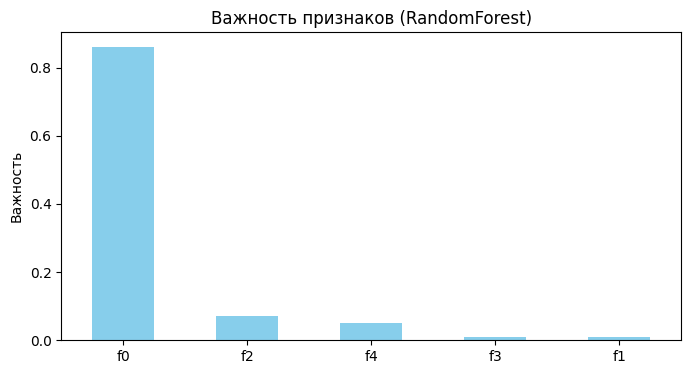

In [20]:
print("Важность признаков")

# 1. Для лучшей модели (LinearRegression) выводим коэффициенты
print("Коэффициенты LinearRegression (по модулю, от большего к меньшему):")
coefs = pd.Series(lr_final.coef_, index=X.columns).sort_values(key=abs, ascending=False)
print(coefs.round(4))

# 2. Для RandomForest выводим feature_importances_
print("\nВажность признаков RandomForest (feature_importances_):")
importances = pd.Series(rf_final.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.round(4))

# 3. Визуализация (чтобы было красиво на защите)
plt.figure(figsize=(8, 4))
importances.plot(kind='bar', color='skyblue')
plt.title('Важность признаков (RandomForest)')
plt.ylabel('Важность')
plt.xticks(rotation=0)
plt.show()